# 과제03 — 원자재는 국내 자산 포트폴리오를 더 좋게 만드는가 (데기투 8조)

김태혁·박종해·공봉재·권일준(2008, 재무관리논총 14(1))의 한국 부분 따라하기와 확장연구 세 가지.
위에서 아래로 한 번 돌리면 보고서의 표 1~8, 부록 A와 그림 1~5가 차례로 나온다.

- `Project_8조_data.txt`의 링크에서 받은 `data` 폴더를 이 노트북 옆에 둔다.
- 계산 함수는 `공통/`에 있다. 결과 표는 `결과/`에 CSV로도 저장된다.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib import font_manager

sys.path.insert(0, str(Path.cwd() / '공통'))
import 자료 as A
import 국면
import 배분
import 모멘텀 as M
import 성과 as P
import 확장자료 as E
from 최적화 import 프런티어, 통계, 최소분산, 위험

R = Path('결과')
R.mkdir(exist_ok=True)

있는글꼴 = {f.name for f in font_manager.fontManager.ttflist}
한글 = next(f for f in ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'Noto Sans CJK KR'] if f in 있는글꼴)
plt.rcParams.update({'font.family': 한글, 'axes.unicode_minus': False, 'font.size': 9})
pd.set_option('display.float_format', '{:.2f}'.format)

## 1. 따라하기: 전체 기간 (원문 표4 c)
공매도·차입 없이, 월 표준편차가 목표 이하인 포트폴리오 가운데 기대수익이 가장 큰 비중.
국고채 3년 금리가 1995년 5월부터 있어 142개월을 쓴다.

표 1. 우리 결과 (142개월, %)


,위험,수익,원자재,주식,국채,회사채,부동산
최소분산,0.22,0.44,0.00,0.33,61.55,0.00,38.11
원문 위험 0.27,0.27,0.63,0.00,0.47,36.98,57.06,5.48
원문 위험 0.28,0.28,0.65,0.00,0.48,30.52,66.77,2.22
원문 위험 0.29,0.29,0.67,0.00,0.48,17.62,81.90,0.00
원문 위험 0.95,0.95,0.69,17.22,0.00,0.00,82.78,0.00
원문 위험 2.65,2.65,0.70,50.67,0.00,0.00,49.33,0.00
원문 위험 4.37,4.37,0.71,84.03,0.00,0.00,15.97,0.00
원문 위험 6.1,5.19,0.71,100.00,0.00,0.00,0.00,0.00


표 2. 원문 표4 c 한국 (p.30)


,위험,수익,GSCI,주식,국채,회사채,부동산
0,0.26,0.60,0.00,0.87,90.68,0.00,8.45
1,0.27,0.63,0.07,0.77,80.03,16.93,2.19
2,0.28,0.67,0.19,0.77,37.99,61.06,0.00
3,0.29,0.69,0.20,0.77,8.55,90.47,0.00
4,0.95,0.71,12.95,0.00,0.00,87.05,0.00
5,2.65,0.73,37.82,0.00,0.00,62.18,0.00
6,4.37,0.75,62.69,0.00,0.00,37.31,0.00
7,6.10,0.77,87.56,0.00,0.00,12.44,0.00


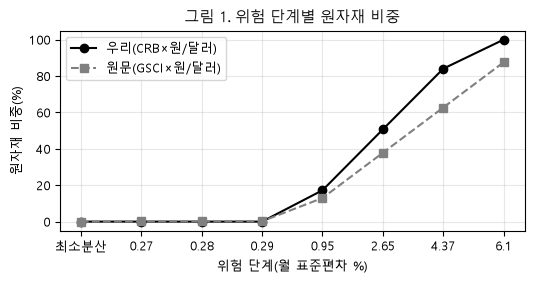

In [2]:
자산 = ['원자재_CRB원화', '주식', '국고채', '회사채', '부동산_PPI']
열이름 = {'실제위험': '위험', '기대수익': '수익', '원자재_CRB원화': '원자재', '국고채': '국채', '부동산_PPI': '부동산'}
위험목표 = [0.26, 0.27, 0.28, 0.29, 0.95, 2.65, 4.37, 6.10]   # 원문 p.30

x = A.월수익률().loc['1995-05':'2007-02', 자산]
S = 통계(x)[1]
# 원문 첫 줄(0.26)은 원문 통계로 다시 풀면 최소분산 포트폴리오라서 첫 줄은 우리 자료의 최소분산으로 둔다
목표 = [위험(최소분산(S), S)] + 위험목표[1:]
표4 = 프런티어(x, 목표)
표4.index = ['최소분산'] + [f'원문 위험 {g}' for g in 위험목표[1:]]
표4.to_csv(R / '표4_전체기간_한국.csv', encoding='utf-8-sig')

원문4 = pd.DataFrame(
    [[0.26, 0.60, 0.00, 0.87, 90.68, 0.00, 8.45],
     [0.27, 0.63, 0.07, 0.77, 80.03, 16.93, 2.19],
     [0.28, 0.67, 0.19, 0.77, 37.99, 61.06, 0.00],
     [0.29, 0.69, 0.20, 0.77, 8.55, 90.47, 0.00],
     [0.95, 0.71, 12.95, 0.00, 0.00, 87.05, 0.00],
     [2.65, 0.73, 37.82, 0.00, 0.00, 62.18, 0.00],
     [4.37, 0.75, 62.69, 0.00, 0.00, 37.31, 0.00],
     [6.10, 0.77, 87.56, 0.00, 0.00, 12.44, 0.00]],
    columns=['위험', '수익', 'GSCI', '주식', '국채', '회사채', '부동산'])

print(f'표 1. 우리 결과 ({len(x)}개월, %)')
display(표4[['실제위험', '기대수익', *자산]].rename(columns=열이름))
print('표 2. 원문 표4 c 한국 (p.30)')
display(원문4)

fig, ax = plt.subplots(figsize=(6, 2.6))
ax.plot(표4['원자재_CRB원화'].values, 'o-', color='black', label='우리(CRB×원/달러)')
ax.plot(원문4['GSCI'].values, 's--', color='gray', label='원문(GSCI×원/달러)')
ax.set_xticks(range(8), ['최소분산'] + [str(g) for g in 위험목표[1:]])
ax.set(xlabel='위험 단계(월 표준편차 %)', ylabel='원자재 비중(%)', title='그림 1. 위험 단계별 원자재 비중')
ax.legend()
ax.grid(alpha=.3)
plt.show()

## 2. 따라하기: 금리 국면별 (원문 표5, 표7)
재할인율의 최근 변화가 하락이면 확장기, 상승이면 긴축기이고 방향이 바뀐 달은 뺀다(원문 p.22).
국면은 재할인율(~1999.04)에 기준금리(1999.05~)를 이어 붙여 나누고, CD 91일로 나눈 결과를 보조로 본다.

In [3]:
def 원문기간수익률():
    r = A.월수익률()
    r.index = r.index.to_period('M')
    return r.loc['1995-01':'2007-02']


def 국면별(금리, r, 자산, 위험단계):
    이름표 = 국면.이름표(국면.후보[금리](), '1995-01', '2007-02')
    줄 = []
    for 국 in ['긴축', '확장']:
        t = r.loc[이름표[이름표 == 국].index, 자산].dropna()
        for g in 위험단계[국]:
            row = 프런티어(t, [g]).iloc[0]
            상태 = '목표보다 낮은 위험에서 이미 수익 최대' if row['실제위험'] < g - 1e-6 else ''
            줄.append({'국면': 국, '달수': len(t), '위험목표': g, **row, '상태': 상태})
    return pd.DataFrame(줄)


r = 원문기간수익률()
단계5 = {'긴축': [0.25, 0.29, 0.80, 1.97, 3.18, 4.38, 5.59, 6.80],   # 원문 p.31
         '확장': [0.25, 0.27, 0.80, 2.52, 4.27, 6.02, 7.78, 9.54]}
단계7 = {'긴축': [0.25, 0.79, 1.22, 1.43, 1.65, 1.87, 2.09, 2.31, 2.53, 2.74, 2.96, 3.18, 3.40, 3.62, 4.06],   # 원문 p.35
         '확장': [0.25, 0.81, 1.30, 1.80, 2.30, 2.81, 3.31, 3.82, 4.33, 4.84, 5.35, 5.94, 6.70, 7.57, 9.54]}
자산7 = ['원자재_CRB달러', '주식', '원달러', '국고채', '회사채', '부동산_PPI']

표5, 표7 = {}, {}
for 금리 in [국면.본국면, 국면.보조국면]:
    파일 = 금리.replace(' ', '_')
    표5[금리] = 국면별(금리, r, 자산, 단계5)
    표7[금리] = 국면별(금리, r, 자산7, 단계7)
    표5[금리].to_csv(R / f'표5_국면별_한국_{파일}.csv', index=False, encoding='utf-8-sig')
    표7[금리].to_csv(R / f'표7_환율분리_한국_{파일}.csv', index=False, encoding='utf-8-sig')

앞열 = ['국면', '달수', '위험목표', '실제위험', '기대수익']
print('표 3. 재할인율→기준금리 국면 (원문 표5, %)')
display(표5[국면.본국면][[*앞열, *자산, '상태']].rename(columns=열이름))
print('보조: CD 91일 국면')
display(표5[국면.보조국면][[*앞열, *자산]].rename(columns=열이름))

표 3. 재할인율→기준금리 국면 (원문 표5, %)


,국면,달수,위험목표,위험,수익,원자재,주식,국채,회사채,부동산,상태
0,긴축,38,0.25,0.25,0.54,4.34,0.00,0.00,95.66,0.00,
1,긴축,38,0.29,0.29,0.54,5.40,0.00,0.00,94.60,0.00,
2,긴축,38,0.80,0.80,0.58,17.78,0.00,0.00,82.22,0.00,
3,긴축,38,1.97,1.97,0.65,45.24,0.00,0.00,54.76,0.00,
4,긴축,38,3.18,3.18,0.73,73.52,0.00,0.00,26.48,0.00,
5,긴축,38,4.38,4.31,0.80,100.00,0.00,0.00,0.00,0.00,목표보다 낮은 위험에서 이미 수익 최대
6,긴축,38,5.59,4.31,0.80,100.00,0.00,0.00,0.00,0.00,목표보다 낮은 위험에서 이미 수익 최대
7,긴축,38,6.80,4.31,0.80,100.00,0.00,0.00,0.00,0.00,목표보다 낮은 위험에서 이미 수익 최대
8,확장,99,0.25,0.25,0.54,0.00,0.55,73.61,0.00,25.84,
9,확장,99,0.27,0.27,0.64,0.00,0.71,72.95,15.27,11.07,


보조: CD 91일 국면


,국면,달수,위험목표,위험,수익,원자재,주식,국채,회사채,부동산
0,긴축,42,0.25,0.25,0.60,0.00,0.08,85.75,14.16,0.00
1,긴축,42,0.29,0.29,0.63,0.00,0.00,39.70,60.30,0.00
2,긴축,42,0.80,0.80,0.83,12.25,0.00,0.00,87.75,0.00
3,긴축,42,1.97,1.97,1.17,38.42,0.00,0.00,61.58,0.00
4,긴축,42,3.18,3.18,1.52,65.02,0.00,0.00,34.98,0.00
5,긴축,42,4.38,4.38,1.87,91.32,0.00,0.00,8.68,0.00
6,긴축,42,5.59,4.78,1.98,100.00,0.00,0.00,0.00,0.00
7,긴축,42,6.80,4.78,1.98,100.00,0.00,0.00,0.00,0.00
8,확장,61,0.25,0.25,0.64,0.35,0.58,0.00,91.32,7.76
9,확장,61,0.27,0.27,0.69,0.20,1.08,0.00,98.72,0.00


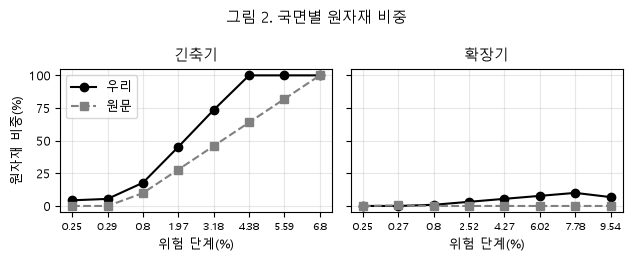

표 4. 원자재(달러)와 원/달러를 따로 넣은 결과 (원문 표7, %)


,국면,달수,위험목표,위험,수익,원자재($),주식,원/달러,국채,회사채,부동산
0,긴축,38,0.25,0.25,0.54,4.61,0.00,0.00,0.00,95.39,0.00
1,긴축,38,0.79,0.79,0.58,17.80,0.00,0.00,0.00,82.20,0.00
2,긴축,38,1.22,1.22,0.61,27.89,0.00,0.00,0.00,72.11,0.00
3,긴축,38,1.43,1.43,0.63,32.80,0.00,0.00,0.00,67.20,0.00
4,긴축,38,1.65,1.65,0.64,37.93,0.00,0.00,0.00,62.07,0.00
5,긴축,38,1.87,1.87,0.66,43.07,0.00,0.00,0.00,56.93,0.00
6,긴축,38,2.09,2.09,0.67,48.19,0.00,0.00,0.00,51.81,0.00
7,긴축,38,2.31,2.31,0.69,53.32,0.00,0.00,0.00,46.68,0.00
8,긴축,38,2.53,2.53,0.70,58.44,0.00,0.00,0.00,41.56,0.00
9,긴축,38,2.74,2.74,0.72,63.33,0.00,0.00,0.00,36.67,0.00


In [4]:
원문5_GSCI = {'긴축': [0.00, 0.00, 9.85, 27.88, 45.91, 63.94, 81.97, 100.0],   # 원문 p.31
              '확장': [0.00, 0.42, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00]}

fig, axs = plt.subplots(1, 2, figsize=(6.4, 2.6), sharey=True)
for ax, 국 in zip(axs, ['긴축', '확장']):
    t = 표5[국면.본국면].query('국면 == @국')
    ax.plot(t['원자재_CRB원화'].values, 'o-', color='black', label='우리')
    ax.plot(원문5_GSCI[국], 's--', color='gray', label='원문')
    ax.set_xticks(range(8), [str(g) for g in t['위험목표']], fontsize=7)
    ax.set(title=f'{국}기', xlabel='위험 단계(%)')
    ax.grid(alpha=.3)
axs[0].set_ylabel('원자재 비중(%)')
axs[0].legend()
fig.suptitle('그림 2. 국면별 원자재 비중')
fig.tight_layout()
plt.show()

print('표 4. 원자재(달러)와 원/달러를 따로 넣은 결과 (원문 표7, %)')
display(표7[국면.본국면][[*앞열, *자산7]].rename(columns={**열이름, '원자재_CRB달러': '원자재($)', '원달러': '원/달러'}))

### 부록 A. 국면 금리 후보 (1995.01~2007.02, 달 수)

In [5]:
def 총액한도_기준금리():
    return 국면.잇기(국면.후보['총액한도대출금리(일간)'](), 국면.후보['기준금리(일간, 1999-05~)']())


후보 = {k: v for k, v in 국면.후보.items() if k not in ('총액한도대출금리(월간)', 국면.본국면)}
후보['잇기: IMF 재할인율→기준금리'] = 국면.후보[국면.본국면]
후보['잇기: 총액한도대출금리→기준금리'] = 총액한도_기준금리

달수 = {k: 국면.이름표(f(), '1995-01', '2007-02').value_counts() for k, f in 후보.items()}
부록A = pd.DataFrame(달수).T.reindex(columns=['확장', '긴축', '혼합', '모름']).fillna(0).astype(int)
display(부록A)

,확장,긴축,혼합,모름
총액한도대출금리(일간),89,12,1,44
IMF 한국 재할인율(월간),135,8,3,0
"기준금리(일간, 1999-05~)",42,39,4,61
정부대출금금리(일간),6,22,1,117
콜금리 1일(일간),0,0,146,0
무담보콜금리 1일(월간),53,44,49,0
CD 91일(월간),62,44,40,0
통안증권 1년(월간),62,43,41,0
잇기: IMF 재할인율→기준금리,103,38,5,0
잇기: 총액한도대출금리→기준금리,59,38,5,44


### 참고 1. 국면별 차이가 우연인지 보는 시뮬레이션 (보고서에는 없음)
확장기와 긴축기의 월평균 수익률 차이가 우연보다 큰지 본다.
p: 국면 이름표를 같은 달 수로 5,000번 섞었을 때 차이가 실제보다 크게 나온 비율.
p밀기: 이름표 줄을 1~145달 통째로 밀었을 때의 비율(국면이 몇 달씩 이어지는 점을 살림).

In [6]:
def 국면차이(y, 이름표):
    y, 이름표 = y[~np.isnan(y)], 이름표[~np.isnan(y)]
    확장, 긴축 = y[이름표 == '확장'], y[이름표 == '긴축']
    if len(확장) < 2 or len(긴축) < 2:
        return np.nan
    return 확장.mean() - 긴축.mean()


rng = np.random.default_rng(20261121)
줄 = []
for 금리, f in 후보.items():
    이름표 = 국면.이름표(f(), '1995-01', '2007-02')
    row = {'후보': 금리}
    for 표시, c in {'주식': '주식', '원자재': '원자재_CRB원화', '부동산': '부동산_PPI', '국고채': '국고채', '회사채': '회사채'}.items():
        y = r[c].dropna()
        L = 이름표.reindex(y.index).values
        y, L = y.values[np.isin(L, ['확장', '긴축'])], L[np.isin(L, ['확장', '긴축'])]
        차 = 국면차이(y, L)
        if np.isnan(차):
            continue
        섞음 = np.array([국면차이(y, rng.permutation(L)) for _ in range(5000)])
        전체 = 이름표.reindex(r.index).values
        밀림 = np.array([국면차이(r[c].values, np.roll(전체, k)) for k in range(1, len(전체))])
        밀림 = 밀림[~np.isnan(밀림)]
        row |= {f'{표시} 차이': 차, f'{표시} p': (abs(섞음) >= abs(차)).mean(), f'{표시} p밀기': (abs(밀림) >= abs(차)).mean()}
    줄.append(row)

열 = [f'{a} {b}' for a in ('주식', '원자재', '부동산') for b in ('차이', 'p', 'p밀기')]
display(pd.DataFrame(줄).set_index('후보')[열].round(3))

,주식 차이,주식 p,주식 p밀기,원자재 차이,원자재 p,원자재 p밀기,부동산 차이,부동산 p,부동산 p밀기
후보,,,,,,,,,
총액한도대출금리(일간),1.42,0.61,0.71,1.28,0.39,0.45,-0.07,0.36,0.53
IMF 한국 재할인율(월간),-0.92,0.79,0.78,2.44,0.18,0.22,-0.03,0.80,0.88
"기준금리(일간, 1999-05~)",3.76,0.03,0.19,-0.39,0.70,0.82,-0.05,0.34,0.72
정부대출금금리(일간),0.41,0.86,0.92,-0.34,0.88,0.93,-0.03,0.73,0.88
콜금리 1일(일간),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
무담보콜금리 1일(월간),2.98,0.16,0.22,-2.89,0.01,0.02,-0.12,0.09,0.10
CD 91일(월간),2.04,0.30,0.41,-1.49,0.15,0.26,-0.04,0.60,0.55
통안증권 1년(월간),0.76,0.68,0.74,-2.77,0.01,0.03,-0.09,0.18,0.22
잇기: IMF 재할인율→기준금리,1.91,0.30,0.44,-0.06,0.95,0.97,-0.05,0.40,0.67


### 참고 2. 채권 총수익률 확인 (보고서에는 없음)
확장2·3에 쓴 채권 총수익률(월말 금리, Swinkels 2019 식)과 원문 식(월평균 금리 이자만)을
DataGuide 국고채 총수익지수(FBI.KTB.01.2)와 비교한다.

In [7]:
k = pd.read_excel(A.D / 'DataGuide/채권지수/bond_tr_index.xlsx', header=None)
지수 = pd.Series(pd.to_numeric(k.iloc[14:, 1], errors='coerce').values, pd.to_datetime(k.iloc[14:, 0]))
비교 = pd.concat({'국고채 총수익지수': 100 * A.월말(지수).pct_change(),
                  '총수익률(확장2·3)': A.월수익률_확장()['국고채'],
                  '원문 식(따라하기)': A.월수익률()['국고채']}, axis=1).loc['2004-07':'2026-08'].dropna()
display(pd.DataFrame({'월평균(%)': 비교.mean(), '월 표준편차(%)': 비교.std(), '지수와 상관': 비교.corr().iloc[0]}).round(3))

,월평균(%),월 표준편차(%),지수와 상관
국고채 총수익지수,0.27,0.66,1.00
총수익률(확장2·3),0.26,0.68,0.99
원문 식(따라하기),0.25,0.10,0.15


## 3. 확장1: 원자재 수단 바꾸기 (기간 B, 원문에 없는 우리 추가)
원자재 자리에 KRX 금현물, 원자재 선물 ETF 7개(수정주가), 코스피 건설·통신을 하나씩 넣고
원자재가 없는 포트폴리오와 같은 위험에서 기대수익을 비교한다.
업종은 이윤정·윤성민(2022)과 전지홍 외(2016)가 공통으로 유가에 반응한다고 보고한 것이다.

기간 B 2017.01~2026.09, 117개월
표 5. 위험 단계별 수단 비중(%)과 원자재가 없을 때보다 늘어난 기대수익(월 %p)


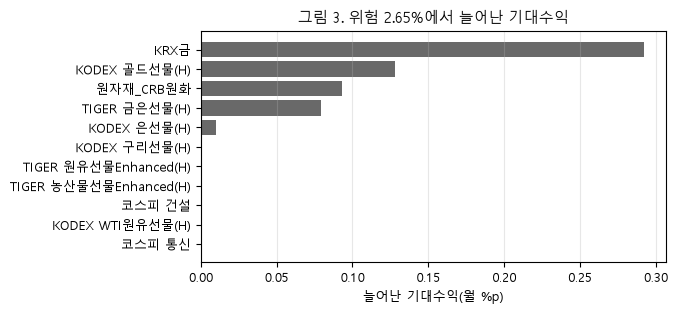

In [8]:
기본 = ['주식', '국고채', '회사채', '부동산_PPI']
e = E.확장1수익률()
처음, 끝 = E.기간B(e)
rb = pd.concat([A.월수익률(), e], axis=1).loc[처음:끝]

없음 = 프런티어(rb[기본], 위험목표)
줄 = []
for 수단 in ['원자재_CRB원화', *e.columns]:
    f = 프런티어(rb[기본 + [수단]], 위험목표)
    줄.append(pd.DataFrame({'수단': 수단, '수단 비중': f[수단], '기대수익 증가': f['기대수익'] - 없음['기대수익'],
                            '실제위험': f['실제위험'], '원자재 없을 때 실제위험': 없음['실제위험']}))
확장1 = pd.concat(줄).reset_index()
확장1.to_csv(R / '확장1_원자재수단_기간B.csv', index=False, encoding='utf-8-sig')

표5_확장1 = (확장1[확장1['위험목표'].isin([0.95, 2.65, 4.37])]
             .pivot(index='수단', columns='위험목표', values=['수단 비중', '기대수익 증가'])
             .sort_values(('기대수익 증가', 2.65), ascending=False).round(3) + 0)
print(f'기간 B {처음:%Y.%m}~{끝:%Y.%m}, {len(rb)}개월')
print('표 5. 위험 단계별 수단 비중(%)과 원자재가 없을 때보다 늘어난 기대수익(월 %p)')
display(표5_확장1.style.format('{:.3f}'))

증가 = 표5_확장1[('기대수익 증가', 2.65)]
fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(증가.index, 증가, color='dimgray')
ax.invert_yaxis()
ax.set(xlabel='늘어난 기대수익(월 %p)', title='그림 3. 위험 2.65%에서 늘어난 기대수익')
ax.grid(alpha=.3, axis='x')
plt.show()

## 4. 확장2: 환율 분리와 배분 방식 (기간 A, 원문에 없는 우리 추가)
매달 지난 60개월로 비중을 정하고 매달 다시 맞춘다(박찬·양기성 2022).
거래 비용은 사고판 비중 합 × 0.5%(Kirby·Ostdiek 2012의 방식, 0.5%는 대신증권 2025).
채권은 가격 변동을 넣은 총수익률(Swinkels 2019)을 본 결과로 쓰고, 원문 식 채권과 비용 0·0.25%는 강건성 확인으로 같이 계산한다.

표 6. 비용 0.5%, 채권 총수익률 (2000-06~2026-09, %)


연수익  연표준편차    샤프   최대낙폭  월회전
판      방식                                
원화 원자재 동일비중 5.16   5.94  0.36 -13.54 2.20
       위험균형 2.42   1.01 -0.71  -1.60 1.64
       최소분산 1.69   0.59 -2.26  -0.86 1.11
환율 분리  동일비중 4.39   4.93  0.27 -10.86 2.20
       위험균형 2.39   1.00 -0.75  -1.05 1.95
       최소분산 1.69   0.60 -2.24  -0.86 1.38
부동산 제외 동일비중 6.01   7.42  0.41 -16.96 2.50
       위험균형 4.50   2.87  0.48  -5.09 1.89
       최소분산 3.75   2.55  0.25  -5.60 7.84

강건성: 원문 식 채권, 비용 0.5%


연수익  연표준편차    샤프   최대낙폭  월회전
판      방식                                
원화 원자재 동일비중 4.92   6.01  0.31 -14.45 2.15
       위험균형 3.26   0.45  0.35  -0.04 1.63
       최소분산 2.92   0.48 -0.66  -0.35 6.80
환율 분리  동일비중 4.20   4.99  0.23 -11.62 2.16
       위험균형 3.21   0.48  0.18  -0.06 1.86
       최소분산 2.92   0.48 -0.69  -0.35 6.82
부동산 제외 동일비중 5.71   7.51  0.36 -18.07 2.44
       위험균형 3.77   0.53  1.73  -0.04 0.89
       최소분산 3.23   0.49  0.24  -0.29 5.59

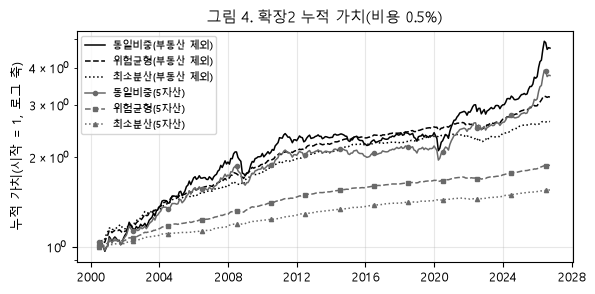

In [9]:
def 성과보기(t):
    t = t[['연환산', '표준편차(연)', '샤프', 'MDD', '월평균 회전']].astype(float)
    t.columns = ['연수익', '연표준편차', '샤프', '최대낙폭', '월회전']
    return t * [100, 100, 1, 100, 100]


def 누적그림(결과, 선들, 제목):
    모양 = [('black', '-', None), ('black', '--', None), ('black', ':', None),
            ('dimgray', '-', 'o'), ('dimgray', '--', 's'), ('dimgray', ':', '^')]
    fig, ax = plt.subplots(figsize=(6.4, 3))
    for (키, 라벨), (색, 선, 표식) in zip(선들, 모양):
        ax.plot((1 + 결과[키]['수익']).cumprod(), color=색, ls=선, marker=표식, markevery=24, ms=3, lw=1.1, label=라벨)
    ax.set(yscale='log', ylabel='누적 가치(시작 = 1, 로그 축)', title=제목)
    ax.legend(fontsize=7)
    ax.grid(alpha=.3)
    plt.show()


본 = '채권 총수익(본)'
자료판 = {본: A.월수익률_확장(), '따라하기 자료': A.월수익률()}
판 = {'원화 원자재': ['주식', '국고채', '회사채', '부동산_PPI', '원자재_CRB원화'],
      '환율 분리': ['주식', '국고채', '회사채', '부동산_PPI', '원자재_CRB달러', '원달러'],
      '부동산 제외': ['주식', '국고채', '회사채', '원자재_CRB원화']}   # 생산자물가 부동산은 사고팔 수 없어 따로 본다

결과2 = {}
for 자료이름, rr in 자료판.items():
    rr = rr.loc['1995-06':]   # 채권 총수익률이 1995년 6월부터라 두 판을 같은 달부터 시작
    for 판이름, cols in 판.items():
        for 방식 in 배분.방식들:
            W = 배분.월별비중(rr[cols], 방식)
            for 비용 in (0.005, 0.0025, 0):
                결과2[(자료이름, 판이름, 방식, f'{비용:.2%}')] = P.백테스트(W, rr[cols], 비용)
성과2 = P.성과표(결과2)
성과2.index.names = ['자료', '판', '방식', '비용']
성과2.to_csv(R / '확장2_배분방식_기간A.csv', encoding='utf-8-sig')

print(f"표 6. 비용 0.5%, 채권 총수익률 ({성과2['첫달'].iloc[0]}~{성과2['끝달'].iloc[0]}, %)")
display(성과보기(성과2.xs((본, '0.50%'), level=['자료', '비용'])))
print('강건성: 원문 식 채권, 비용 0.5%')
display(성과보기(성과2.xs(('따라하기 자료', '0.50%'), level=['자료', '비용'])))

선들 = [((본, '부동산 제외', m, '0.50%'), f'{m}(부동산 제외)') for m in 배분.방식들]
선들 += [((본, '원화 원자재', m, '0.50%'), f'{m}(5자산)') for m in 배분.방식들]
누적그림(결과2, 선들, '그림 4. 확장2 누적 가치(비용 0.5%)')

In [10]:
금달러 = 배분.환율분리(E.krx금())[['달러기준']].rename(columns={'달러기준': 'KRX금_달러'})
금 = pd.concat([A.월수익률(), e[['KRX금']], 금달러], axis=1).loc[처음:끝]
금표 = pd.concat({'원화 금': 프런티어(금[기본 + ['KRX금']], 위험목표),
                 '달러 금 + 원달러': 프런티어(금[기본 + ['KRX금_달러', '원달러']], 위험목표)})
금표.to_csv(R / '확장2_금환율분리_기간B.csv', encoding='utf-8-sig')
print('참고: KRX 금을 달러 기준 금과 원/달러로 나눈 효율적 포트폴리오 (기간 B)')
display(금표)

참고: KRX 금을 달러 기준 금과 원/달러로 나눈 효율적 포트폴리오 (기간 B)


주식  국고채   회사채  부동산_PPI   KRX금  기대수익  실제위험  KRX금_달러  원달러
           위험목표                                                           
원화 금       0.26  1.49 0.00 93.96     0.00   4.55  0.30  0.26      NaN  NaN
           0.27  1.55 0.00 93.71     0.00   4.74  0.31  0.27      NaN  NaN
           0.28  1.62 0.00 93.46     0.00   4.92  0.31  0.28      NaN  NaN
           0.29  1.68 0.00 93.21     0.00   5.11  0.31  0.29      NaN  NaN
           0.95  5.66 0.00 77.30     0.00  17.04  0.46  0.95      NaN  NaN
           2.65 15.80 0.00 36.73     0.00  47.47  0.82  2.65      NaN  NaN
           4.37 14.17 0.00  0.00     0.00  85.83  1.17  4.37      NaN  NaN
           6.10  0.00 0.00  0.00     0.00 100.00  1.19  4.88      NaN  NaN
달러 금 + 원달러 0.26  1.42 0.00 93.62     0.00    NaN  0.30  0.26     4.34 0.62
           0.27  1.48 0.00 93.38     0.00    NaN  0.30  0.27     4.51 0.63
           0.28  1.54 0.00 93.13     0.00    NaN  0.30  0.28     4.69 0.64
           0.29  1.60 0.00 92.88     0.00    NaN  0.30  0.29     4.87 0.65
           0.95  5.34 0.00 76.97     0.00    NaN  0.43  0.95    16.22 1.47
           2.65 14.88 0.00 36.40     0.00    NaN  0.74  2.65    45.18 3.55
           4.37 24.21 0.00  0.00     0.00    NaN  1.06  4.37    74.02 1.77
           6.10  0.00 0.00  0.00     0.00    NaN  1.09  4.96   100.00 0.00

## 5. 확장3: 모멘텀 전술 배분 (기간 A, 원문에 없는 우리 추가)
절대 모멘텀은 지난 기간 수익이 무위험수익률(CD 91일)을 넘은 자산만 각자 몫을 갖고, 넘지 못한 몫은 국고채로 옮긴다
(Antonacci 2014, 대신증권 2025). 듀얼 모멘텀은 그중 가장 높은 하나만 갖는다.
관찰 기간은 대신증권의 12개월을 기본으로 하고 수업에서 다룬 3·6·9개월과 비교한다. 교체 비용은 0.5%.
원자재를 넣은 효과를 보려고 원자재를 뺀 판도 같이 돌린다.

표 7. 비용 0.5%, 채권 총수익률, 원문 자산 5개 (1996-02~2026-09, %)


연수익  연표준편차   샤프   최대낙폭   월회전
관찰기간 전략                                     
12개월 절대        5.99   5.88 0.31  -7.14 16.69
     듀얼(상위 1)  7.70  20.73 0.26 -53.42 34.88
3개월  절대        6.48   6.93 0.34 -11.11 35.60
     듀얼(상위 1) 12.43  19.67 0.48 -43.55 67.03
6개월  절대        7.15   6.39 0.46 -15.68 23.02
     듀얼(상위 1)  9.59  20.98 0.34 -71.25 53.41
9개월  절대        6.98   5.87 0.47  -7.14 20.27
     듀얼(상위 1) 11.51  20.65 0.43 -40.73 39.78
비교   동일비중 매월   5.78   7.14 0.23 -13.54  2.44

판별 샤프지수 (비용 0.5%)


자료            채권 총수익(본)                          따라하기 자료                \
판                 원문 자산 부동산 제외 원자재 제외 부동산·원자재 제외   원문 자산 부동산 제외 원자재 제외   
관찰기간 전략                                                                  
12개월 듀얼(상위 1)      0.26   0.26   0.20       0.20    0.23   0.23   0.21   
     절대            0.31   0.28   0.33       0.30    0.18   0.19   0.22   
3개월  듀얼(상위 1)      0.48   0.48   0.44       0.45    0.37   0.38   0.29   
     절대            0.34   0.37   0.29       0.33    0.27   0.33   0.27   
6개월  듀얼(상위 1)      0.34   0.34   0.37       0.38    0.27   0.27   0.34   
     절대            0.46   0.46   0.39       0.38    0.37   0.39   0.34   
9개월  듀얼(상위 1)      0.43   0.43   0.34       0.34    0.34   0.34   0.26   
     절대            0.47   0.46   0.34       0.33    0.38   0.39   0.28   
비교   동일비중 매월       0.23   0.31   0.19       0.28    0.19   0.27   0.15   

자료                        
판             부동산·원자재 제외  
관찰기간 전략                   
12개월 듀얼(상위 1)       0.21  
     절대             0.23  
3개월  듀얼(상위 1)       0.31  
     절대             0.33  
6개월  듀얼(상위 1)       0.34  
     절대             0.36  
9개월  듀얼(상위 1)       0.26  
     절대             0.29  
비교   동일비중 매월        0.24

판별 최대낙폭 (%, 비용 0.5%)


자료            채권 총수익(본)                          따라하기 자료                \
판                 원문 자산 부동산 제외 원자재 제외 부동산·원자재 제외   원문 자산 부동산 제외 원자재 제외   
관찰기간 전략                                                                  
12개월 듀얼(상위 1)    -53.42 -53.42 -38.81     -38.81  -57.75 -57.75 -42.48   
     절대           -7.14 -10.90 -13.05     -21.64   -9.55 -13.38  -9.75   
3개월  듀얼(상위 1)    -43.55 -43.55 -33.42     -33.42  -51.01 -49.83 -38.64   
     절대          -11.11 -15.60 -14.19     -23.29  -11.70 -15.84  -7.65   
6개월  듀얼(상위 1)    -71.25 -70.82 -48.70     -47.94  -71.64 -71.33 -50.74   
     절대          -15.68 -26.01 -10.64     -18.24  -18.97 -27.96 -10.44   
9개월  듀얼(상위 1)    -40.73 -40.73 -33.97     -33.83  -40.13 -40.13 -30.53   
     절대           -7.14  -9.22  -9.53     -15.07   -6.15  -9.57  -8.19   
비교   동일비중 매월     -13.54 -16.96 -19.80     -27.26  -14.98 -18.26 -11.73   

자료                        
판             부동산·원자재 제외  
관찰기간 전략                   
12개월 듀얼(상위 1)     -42.48  
     절대           -18.06  
3개월  듀얼(상위 1)     -38.64  
     절대           -14.29  
6개월  듀얼(상위 1)     -49.69  
     절대           -18.71  
9개월  듀얼(상위 1)     -30.53  
     절대           -13.40  
비교   동일비중 매월      -15.74

표 8. 원자재를 넣은 판과 뺀 판 (비용 0.5%, 채권 총수익률, 최대낙폭 %)


원문 자산        원자재 제외        원자재 넣은 쪽이 높은 수(4개 중)
                 샤프    MDD     샤프    MDD                     
관찰기간 전략                                                      
12개월 듀얼(상위 1)  0.26 -53.42   0.20 -38.81                    4
     절대        0.31  -7.14   0.33 -13.05                    0
3개월  듀얼(상위 1)  0.48 -43.55   0.44 -33.42                    4
     절대        0.34 -11.11   0.29 -14.19                    3
6개월  듀얼(상위 1)  0.34 -71.25   0.37 -48.70                    0
     절대        0.46 -15.68   0.39 -10.64                    4
9개월  듀얼(상위 1)  0.43 -40.73   0.34 -33.97                    4
     절대        0.47  -7.14   0.34  -9.53                    4
비교   동일비중 매월   0.23 -13.54   0.19 -19.80                    4

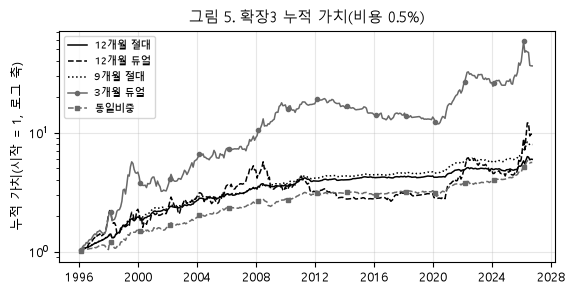

In [11]:
자산판 = {'원문 자산': ['주식', '국고채', '회사채', '부동산_PPI', '원자재_CRB원화'],
         '부동산 제외': ['주식', '국고채', '회사채', '원자재_CRB원화'],
         '원자재 제외': ['주식', '국고채', '회사채', '부동산_PPI'],
         '부동산·원자재 제외': ['주식', '국고채', '회사채']}
rf = P.무위험() * 100

비중들 = {}
for 자료이름, r0 in 자료판.items():
    for 판이름, cols in 자산판.items():
        rr = r0[cols]
        for L in (12, 3, 6, 9):
            비중들[(자료이름, 판이름, f'{L}개월', '절대')] = (M.비중(rr, L, rf.reindex(rr.index)), rr)
            비중들[(자료이름, 판이름, f'{L}개월', '듀얼(상위 1)')] = (M.비중(rr, L, rf.reindex(rr.index), 상위=1), rr)
        비중들[(자료이름, 판이름, '비교', '동일비중 매월')] = (pd.DataFrame(1 / len(cols), rr.dropna().index, cols), rr)

# 모든 전략을 12개월 신호가 처음 생기는 같은 달부터 시작한다
시작 = max(W.dropna().index[0] for W, _ in 비중들.values())
결과3 = {}
for 비용 in (0.005, 0.0025, 0):
    for 키, (W, rr) in 비중들.items():
        결과3[(*키, f'{비용:.2%}')] = P.백테스트(W.loc[시작:], rr, 비용)
성과3 = P.성과표(결과3)
성과3.index.names = ['자료', '판', '관찰기간', '전략', '비용']
성과3.to_csv(R / '확장3_모멘텀_기간A.csv', encoding='utf-8-sig')

print(f"표 7. 비용 0.5%, 채권 총수익률, 원문 자산 5개 ({성과3['첫달'].iloc[0]}~{성과3['끝달'].iloc[0]}, %)")
display(성과보기(성과3.xs((본, '원문 자산', '0.50%'), level=['자료', '판', '비용'])))

비용05 = 성과3.xs('0.50%', level='비용')
샤프 = 비용05['샤프'].astype(float).unstack(['자료', '판'])
print('판별 샤프지수 (비용 0.5%)')
display(샤프)
print('판별 최대낙폭 (%, 비용 0.5%)')
display((비용05['MDD'].astype(float) * 100).unstack(['자료', '판']))

짝 = [('원문 자산', '원자재 제외'), ('부동산 제외', '부동산·원자재 제외')]
표8 = pd.concat({판: 비용05.sort_index().loc[(본, 판), ['샤프', 'MDD']].astype(float) * [1, 100]
                for 판 in ('원문 자산', '원자재 제외')}, axis=1).round(2)
표8['원자재 넣은 쪽이 높은 수(4개 중)'] = sum((샤프[(자, a)] > 샤프[(자, c)]).astype(int) for 자 in 자료판 for a, c in 짝)
print('표 8. 원자재를 넣은 판과 뺀 판 (비용 0.5%, 채권 총수익률, 최대낙폭 %)')
display(표8)

선들 = [((본, '원문 자산', L, s, '0.50%'), 라벨) for L, s, 라벨 in [
    ('12개월', '절대', '12개월 절대'), ('12개월', '듀얼(상위 1)', '12개월 듀얼'), ('9개월', '절대', '9개월 절대'),
    ('3개월', '듀얼(상위 1)', '3개월 듀얼'), ('비교', '동일비중 매월', '동일비중')]]
누적그림(결과3, 선들, '그림 5. 확장3 누적 가치(비용 0.5%)')